# Air Quality Index (AQI) Trend Analysis using Matplotlib
**Dataset:** `city_day.csv` (Kaggle *Air Quality Data in India*) — daily city-wise pollutant levels (PM2.5, PM10, CO) and AQI.

## 1. Import Libraries and Dataset

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11})

CSV_PATH = "city_day.csv"   # put the notebook in the same folder as the file, or give the full path
df = pd.read_csv(CSV_PATH)
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Explore the Dataset

In [18]:
print("Shape:", df.shape)
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().round(2)

Shape: (29531, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB

Missing values:
 City              0
Date              0
PM2.5          4598
PM1

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.00,18391.00,25949.00,25946.00,25346.00,19203.00,27472.00,25677.00,25509.00,23908.00,21490.00,11422.00,24850.00
mean,67.45,118.13,17.57,28.56,32.31,23.48,2.25,14.53,34.49,3.28,8.70,3.07,166.46
std,64.66,90.61,22.79,24.47,31.65,25.68,6.96,18.13,21.69,15.81,19.97,6.32,140.70
min,0.04,0.01,0.02,0.01,0.00,0.01,0.00,0.01,0.01,0.00,0.00,0.00,13.00
25%,28.82,56.26,5.63,11.75,12.82,8.58,0.51,5.67,18.86,0.12,0.60,0.14,81.00
50%,48.57,95.68,9.89,21.69,23.52,15.85,0.89,9.16,30.84,1.07,2.97,0.98,118.00
75%,80.59,149.74,19.95,37.62,40.13,30.02,1.45,15.22,45.57,3.08,9.15,3.35,208.00
max,949.99,1000.00,390.68,362.21,467.63,352.89,175.81,193.86,257.73,455.03,454.85,170.37,2049.00


## 3. Identify Relevant Variables and Clean the Data
The file contains many cities, so one city (and one year, for readable monthly plots) is selected. Change `CITY` and `YEAR` as needed; set `YEAR = None` to use all years.

In [19]:
CITY, YEAR = "Delhi", 2019
DATE_COL, AQI_COL = "Date", "AQI"
POLLUTANTS = ["PM2.5", "PM10", "CO"]
COLORS = {"AQI": "#d62728", "PM2.5": "#1f77b4", "PM10": "#2ca02c", "CO": "#ff7f0e"}

# Select one city and convert the date column to datetime
df = df[df["City"] == CITY].copy()
df["Datetime"] = pd.to_datetime(df[DATE_COL], errors="coerce")
if YEAR:
    df = df[df["Datetime"].dt.year == YEAR]

# Keep relevant columns, drop invalid rows, fill small gaps by interpolation
cols = [AQI_COL] + POLLUTANTS
df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=["Datetime"]).sort_values("Datetime").drop_duplicates("Datetime").set_index("Datetime")
df[cols] = df[cols].interpolate(limit_direction="both")

daily = df[cols].resample("D").mean()
monthly = df[cols].resample("MS").mean()
print(f"City: {CITY}  |  Period: {df.index.min().date()} to {df.index.max().date()}  |  Records: {len(df)}")

City: Delhi  |  Period: 2019-01-01 to 2019-12-31  |  Records: 365


## 4. Overall AQI Trend over Time

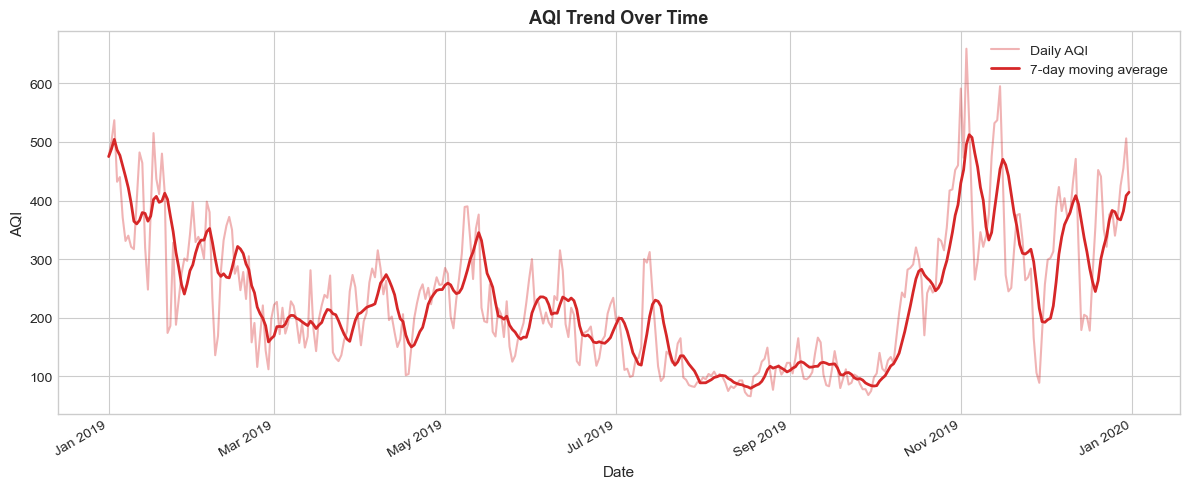

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily.index, daily[AQI_COL], color=COLORS["AQI"], alpha=0.35, label="Daily AQI")
ax.plot(daily.index, daily[AQI_COL].rolling(7, min_periods=1).mean(), color=COLORS["AQI"], lw=2, label="7-day moving average")
ax.set(title="AQI Trend Over Time", xlabel="Date", ylabel="AQI")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 5. Individual Pollutant Trends

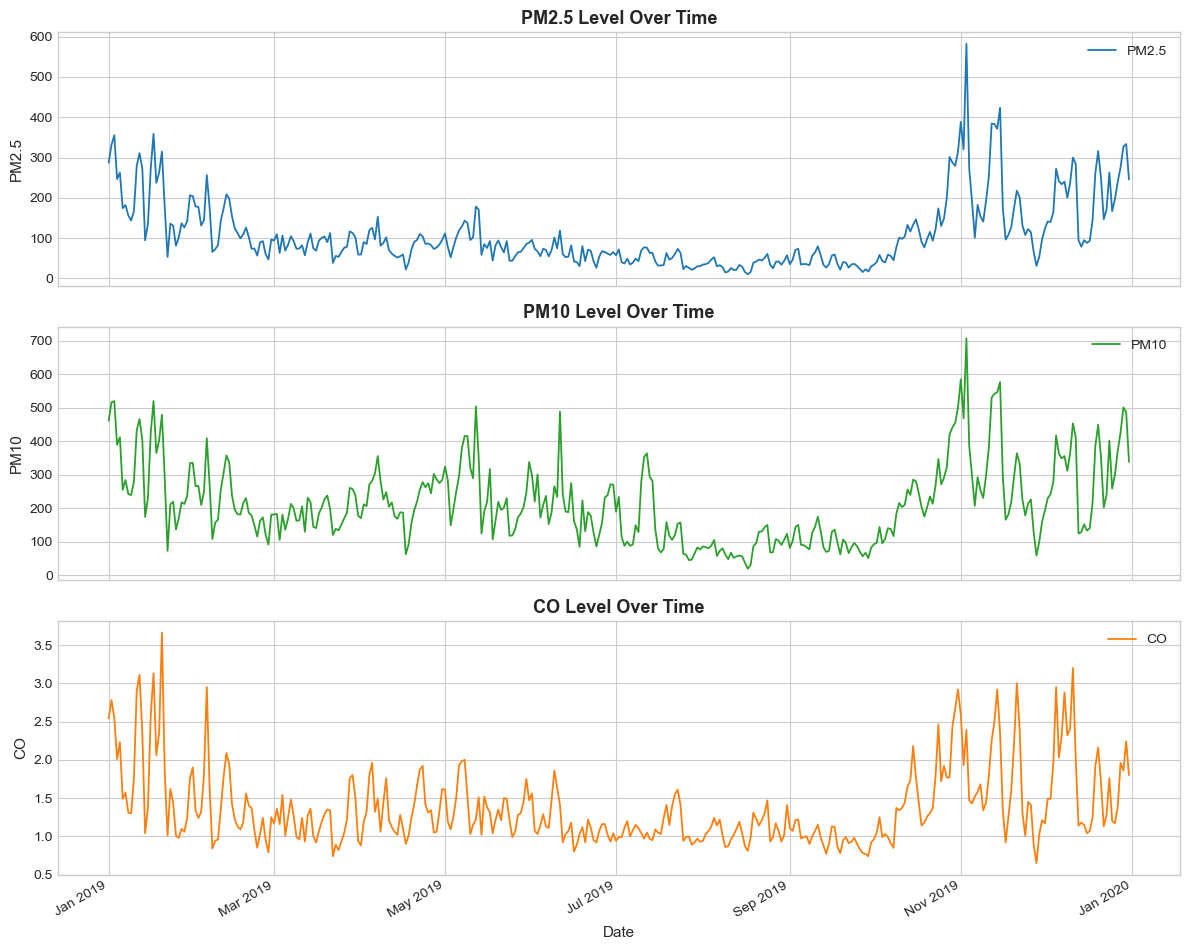

In [21]:
fig, axes = plt.subplots(len(POLLUTANTS), 1, figsize=(12, 3.2 * len(POLLUTANTS)), sharex=True)
for ax, p in zip(axes, POLLUTANTS):
    ax.plot(daily.index, daily[p], color=COLORS[p], lw=1.3, label=p)
    ax.set_ylabel(p)
    ax.set_title(f"{p} Level Over Time")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Date")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 6. Comparing AQI across Time Periods (Bar and Stacked Bar Plots)

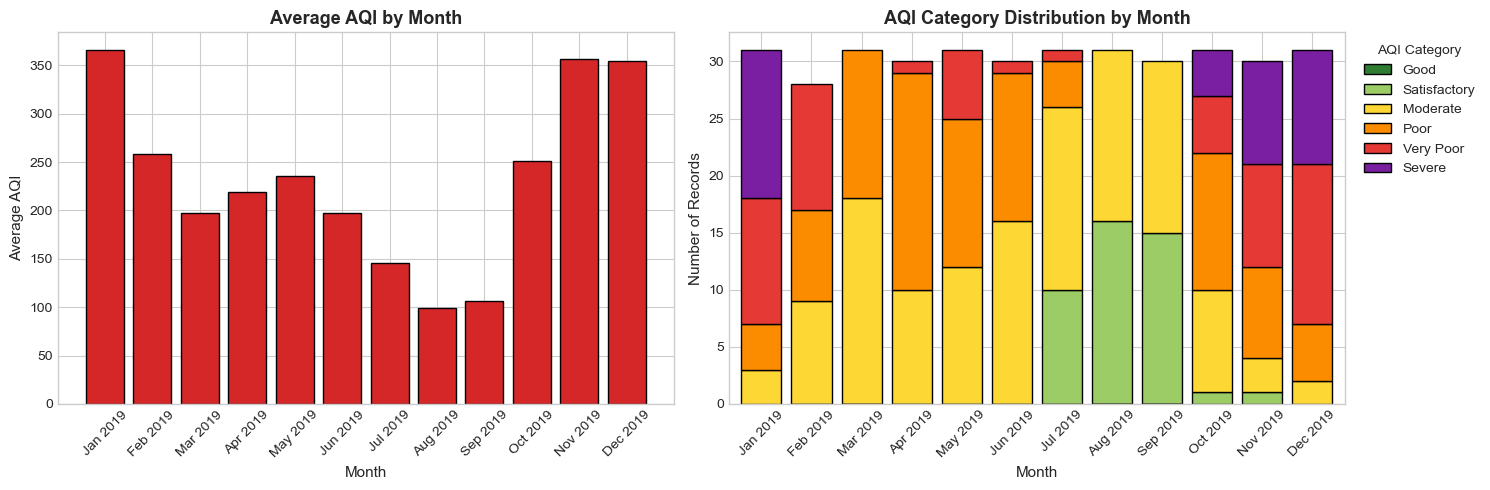

In [22]:
# AQI categories (Indian CPCB scale)
bins   = [0, 50, 100, 200, 300, 400, np.inf]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
cat_colors = ["#2e7d32", "#9ccc65", "#fdd835", "#fb8c00", "#e53935", "#7b1fa2"]
df["AQI_Category"] = pd.cut(df[AQI_COL], bins=bins, labels=labels)

month_lbl = monthly.index.strftime("%b %Y")
cat_counts = df.groupby([pd.Grouper(freq="MS"), "AQI_Category"], observed=False).size().unstack(fill_value=0)
cat_counts.index = cat_counts.index.strftime("%b %Y")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar plot: monthly average AQI
axes[0].bar(month_lbl, monthly[AQI_COL], color=COLORS["AQI"], edgecolor="black")
axes[0].set(title="Average AQI by Month", xlabel="Month", ylabel="Average AQI")

# Stacked bar plot: AQI category distribution by month
cat_counts.plot(kind="bar", stacked=True, ax=axes[1], color=cat_colors, edgecolor="black", width=0.8)
axes[1].set(title="AQI Category Distribution by Month", xlabel="Month", ylabel="Number of Records")
axes[1].legend(title="AQI Category", bbox_to_anchor=(1.01, 1), loc="upper left")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 7. Distribution of AQI across Pollutant Categories (Box and Violin Plots)
Each pollutant is divided into **Low / Medium / High** levels (terciles), and the AQI distribution is compared across them.

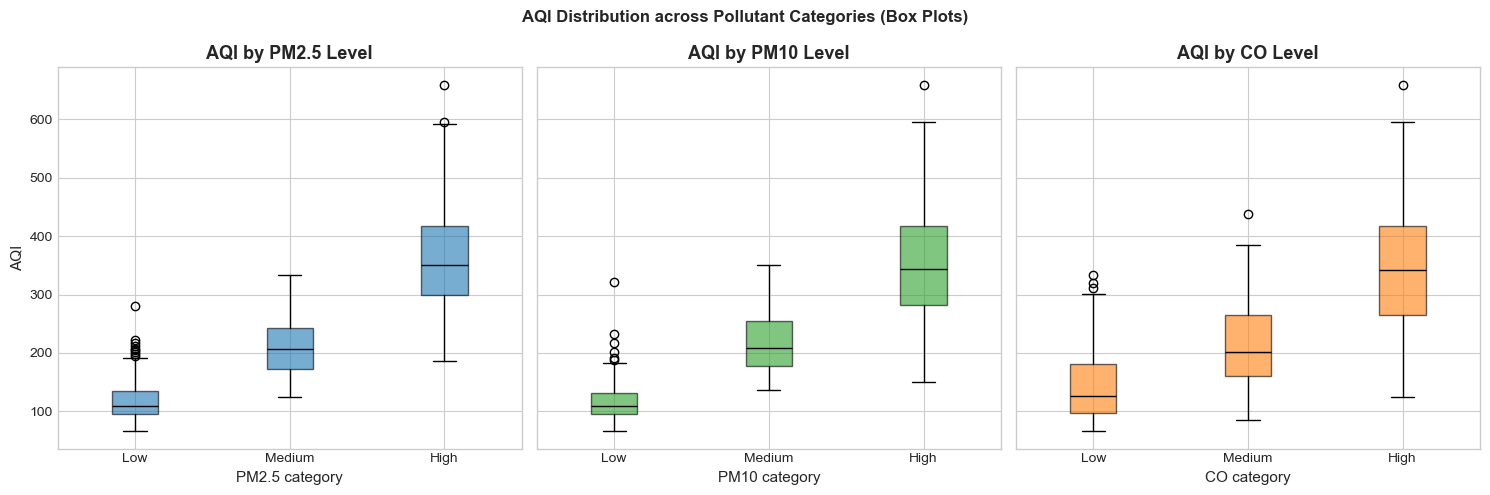

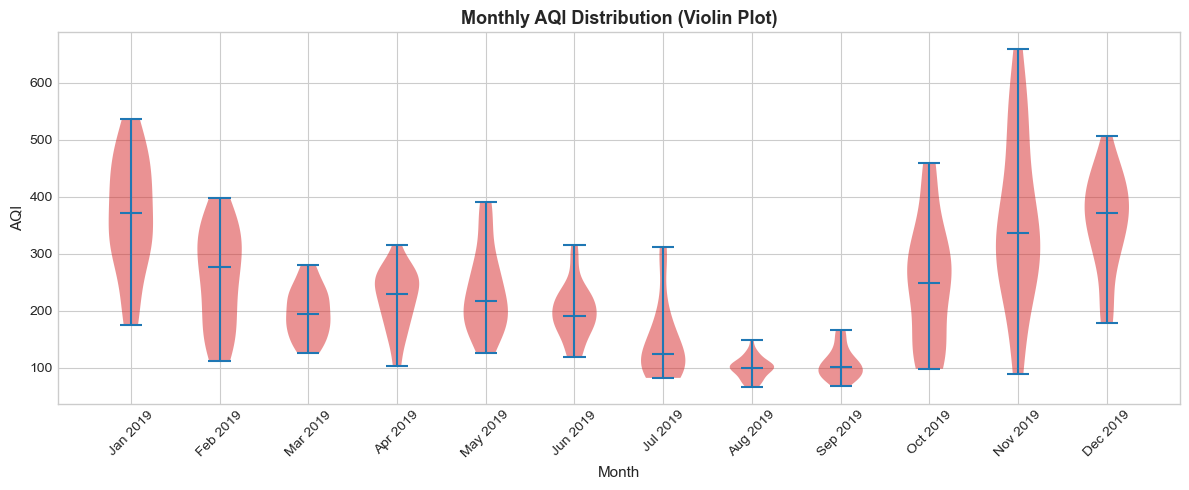

In [23]:
levels = ["Low", "Medium", "High"]
fig, axes = plt.subplots(1, len(POLLUTANTS), figsize=(15, 5), sharey=True)

for ax, p in zip(axes, POLLUTANTS):
    grp = pd.qcut(df[p], 3, labels=levels, duplicates="drop")
    data = [df.loc[grp == l, AQI_COL] for l in levels]
    bp = ax.boxplot(data, tick_labels=levels, patch_artist=True, medianprops={"color": "black"})
    for patch in bp["boxes"]:
        patch.set(facecolor=COLORS[p], alpha=0.6)
    ax.set(title=f"AQI by {p} Level", xlabel=f"{p} category")
axes[0].set_ylabel("AQI")
plt.suptitle("AQI Distribution across Pollutant Categories (Box Plots)", fontweight="bold")
plt.tight_layout()
plt.show()

# Violin plot: AQI distribution by month
months = [g[AQI_COL].values for _, g in df.groupby(pd.Grouper(freq="MS")) if len(g)]
fig, ax = plt.subplots(figsize=(12, 5))
vp = ax.violinplot(months, showmedians=True)
for body in vp["bodies"]:
    body.set(facecolor=COLORS["AQI"], alpha=0.5)
ax.set_xticks(range(1, len(months) + 1))
ax.set_xticklabels(month_lbl[:len(months)], rotation=45)
ax.set(title="Monthly AQI Distribution (Violin Plot)", xlabel="Month", ylabel="AQI")
plt.tight_layout()
plt.show()

## 8. Relationship between AQI and Pollutant Levels (Scatter and Bubble Charts)

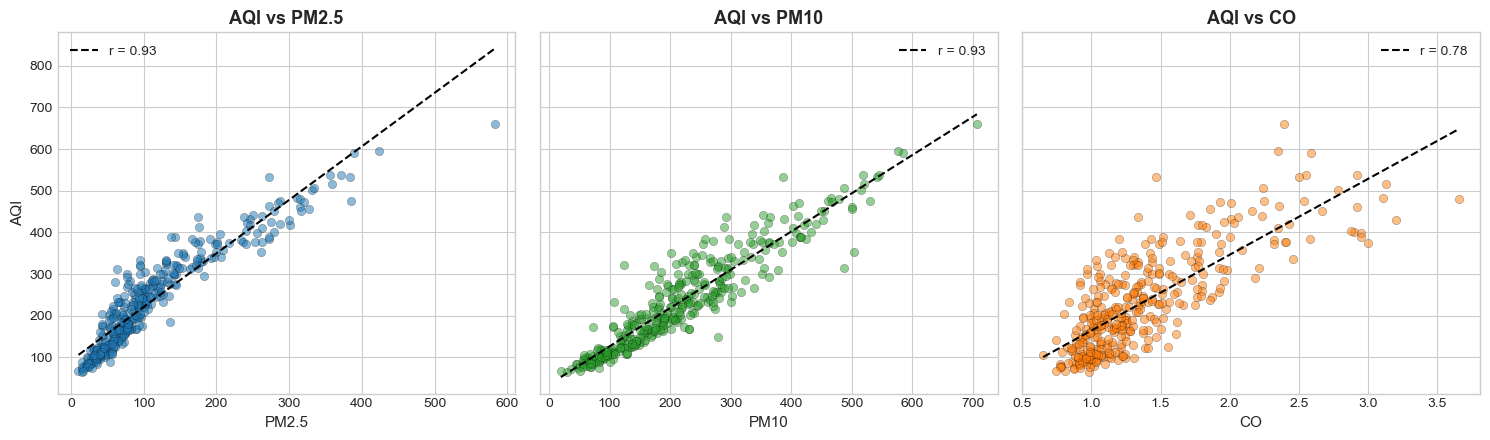

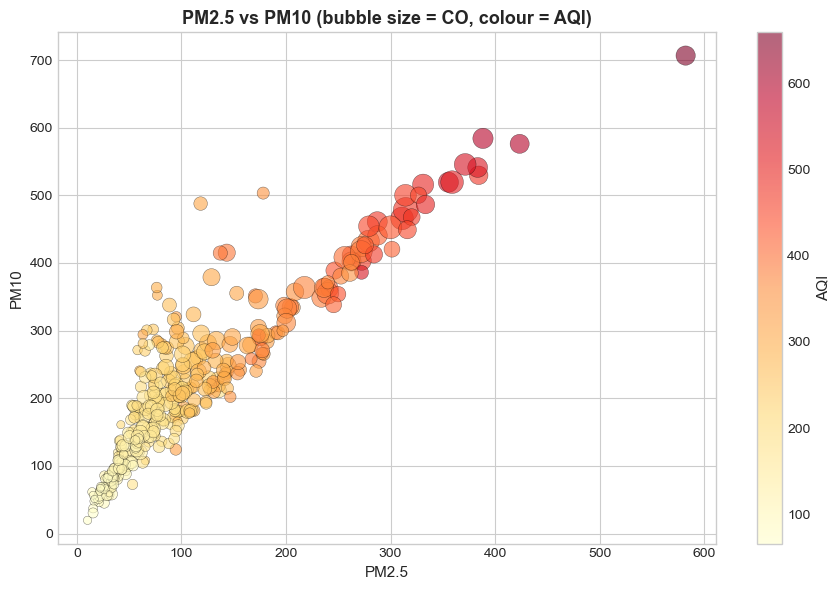

In [24]:
# Scatter plots with trend line and correlation
fig, axes = plt.subplots(1, len(POLLUTANTS), figsize=(15, 4.5), sharey=True)
for ax, p in zip(axes, POLLUTANTS):
    ax.scatter(df[p], df[AQI_COL], color=COLORS[p], alpha=0.5, edgecolor="k", linewidth=0.3)
    m, b = np.polyfit(df[p], df[AQI_COL], 1)
    xs = np.linspace(df[p].min(), df[p].max(), 100)
    ax.plot(xs, m * xs + b, color="black", ls="--", label=f"r = {df[p].corr(df[AQI_COL]):.2f}")
    ax.set(title=f"AQI vs {p}", xlabel=p)
    ax.legend()
axes[0].set_ylabel("AQI")
plt.tight_layout()
plt.show()

# Bubble chart: PM2.5 vs PM10, bubble size = CO, colour = AQI
size = 20 + 300 * (df["CO"] - df["CO"].min()) / (df["CO"].max() - df["CO"].min())
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df["PM2.5"], df["PM10"], s=size, c=df[AQI_COL], cmap="YlOrRd", alpha=0.6, edgecolor="k", linewidth=0.3)
fig.colorbar(sc, label="AQI")
ax.set(title="PM2.5 vs PM10 (bubble size = CO, colour = AQI)", xlabel="PM2.5", ylabel="PM10")
plt.tight_layout()
plt.show()